# MARIO training dashboard - Tasks 1 and 2

This is the notebook entry point for the MARIO DINOv2 + GRU training plan. Its executable cells run the original frozen DINO pipeline used by the command-line tools, while showing original and processed B-scans and updating training and validation plots after every validation epoch.

Validation is intentionally performed once per epoch (not once per minibatch): that is the model-selection cadence in the implementation plan. The live charts show every one of those training/validation steps, for each fold and for Stage A (Task 1) and Stage B (Task 2).

> Before running on challenge data, update the data paths in `configs/base.yaml` or select your own config in the next cell. The default configuration does not include MARIO data or pretrained DINO weights.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import clear_output, display
from sklearn.metrics import confusion_matrix

REPO = Path.cwd().resolve()
if not (REPO / 'mario_dino').is_dir():
    REPO = REPO.parent
assert (REPO / 'mario_dino').is_dir(), 'Open this notebook from the repository or its notebooks/ directory.'
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# Change this to a project-specific YAML file if you keep your data paths outside configs/base.yaml.
CONFIG_PATH = REPO / 'configs' / 'base.yaml'
PYTHON = sys.executable
print(f'Repository: {REPO}')
print(f'Python: {PYTHON}')
print(f'Config: {CONFIG_PATH}')

Repository: D:\yug_mario\mario
Python: d:\yug_mario\mario\.venv\Scripts\python.exe
Config: D:\yug_mario\mario\configs\base.yaml


In [2]:
from mario_dino.config import config_to_dict, load_config
from mario_dino.data import schema
from mario_dino.octip_cache import cache_path, collect_images

cfg = load_config(str(CONFIG_PATH))
CSV_PATHS = cfg.data.task1_train_csvs + cfg.data.task2_train_csvs + cfg.data.extra_csvs
if not CSV_PATHS:
    raise ValueError('No CSV files are configured. Set data.task1_train_csvs and data.task2_train_csvs.')
missing = [p for p in CSV_PATHS if not Path(p).is_file()]
if missing:
    raise FileNotFoundError('Configured CSV files are missing:\n' + '\n'.join(map(str, missing)))

print(yaml.safe_dump(config_to_dict(cfg), sort_keys=False))
images = collect_images(CSV_PATHS, cfg.data.image_roots, cfg.data.include_image_dirs)
print(f'{len(images):,} unique images across {len(CSV_PATHS)} configured CSV file(s).')
print(f'Preprocessing: {cfg.preprocess.mode}; encoder input: {cfg.encoder.img_size[1]} x {cfg.encoder.img_size[0]} (W x H)')

seed: 0
device: auto
class_names:
  task1:
  - reduced
  - stable
  - worsened
  - other
  task2:
  - reduced
  - stable
  - worsened
data:
  image_root: Task_2/train
  image_fallback_roots:
  - Task_1/train
  include_image_dirs:
  - Task_2/train
  task1_train_csvs:
  - Task_1/df_task1_train.csv
  task2_train_csvs:
  - Task_2/df_task2_train.csv
  extra_csvs: []
  splits: outputs/splits.json
  n_folds: 4
preprocess:
  mode: classic
  cache_dir: cache
  octip_weights_dir: weights/octip
  octip_batch_size: 16
encoder:
  name: vit_base_patch14_reg4_dinov2.lvd142m
  weights: weights/vit_base_patch14_reg4_dinov2.lvd142m.pth
  img_size:
  - 196
  - 518
  kwargs: {}
  kind: dinov2
  checkpoint_key: null
  preprocessing: legacy_dino
features:
  store_dir: features/store
  dtype: float16
  batch_size: 64
  chunk_size: 1024
  num_workers: 4
  amp: true
model:
  head_input: pair
  forecaster: gru
  hidden: 512
  dt_dim: 64
  dropout: 0.2
  forecast_steps: 1
train:
  out_dir: outputs/heads
  folds:

10:21:01 WARNING mario_dino.octip_cache: Task_1/df_task1_train.csv: excluding 5 row(s) referencing 3 unreadable image(s): ['1BD348C0.png', '3D28DE10.png', 'C250C570.png']


17,760 unique images across 2 configured CSV file(s).
Preprocessing: classic; encoder input: 518 x 196 (W x H)


## 1. Inspect source B-scans

A small sample before any transformation makes problems with paths, contrast, or orientation obvious.

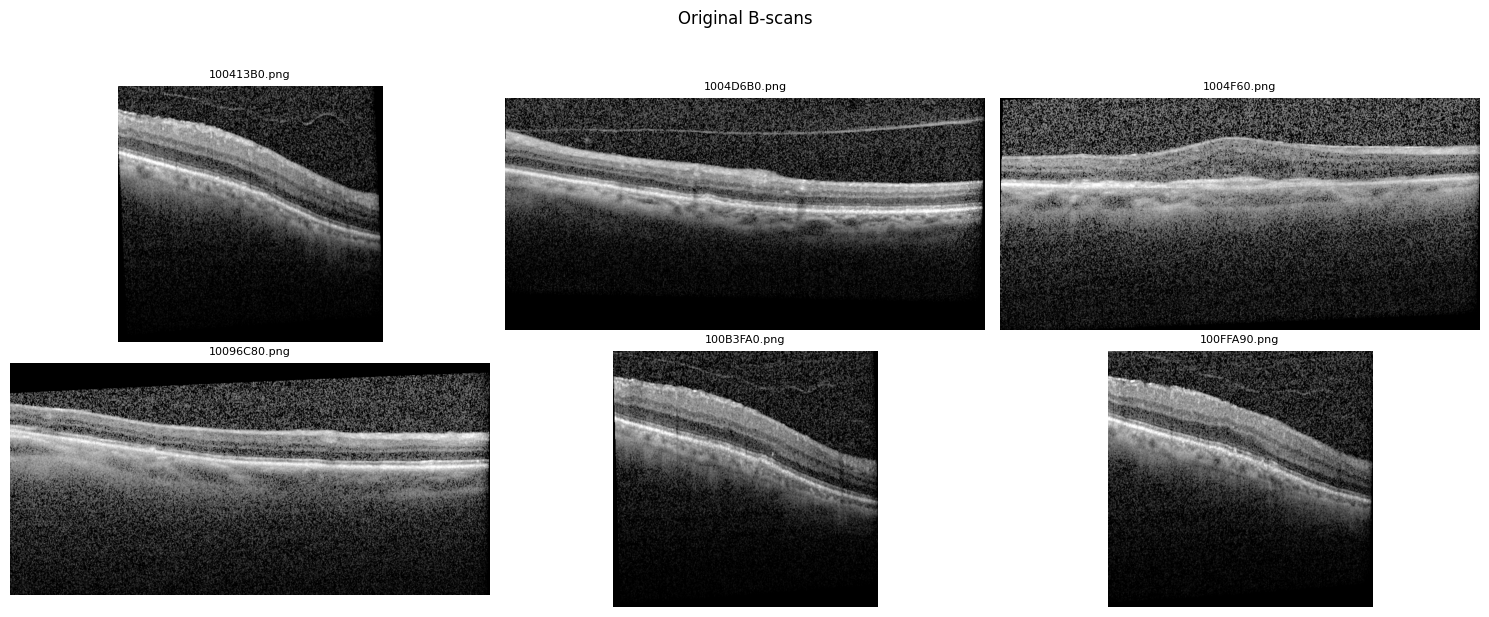

In [ ]:
def source_path(image_name):
    return Path(schema.image_path(cfg.data.image_roots, str(image_name)))

def show_source_samples(names, n=6):
    picked = list(names)[:n]
    fig, axes = plt.subplots(2, 3, figsize=(15, 6))
    for ax, name in zip(axes.flat, picked):
        img = cv2.imread(str(source_path(name)), cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap='gray')
        ax.set_title(str(name), fontsize=8)
        ax.axis('off')
    for ax in axes.flat[len(picked):]:
        ax.axis('off')
    fig.suptitle('Original B-scans', y=1.02)
    fig.tight_layout()

show_source_samples(images)

## 2. Prepare folds and encoder weights

Folds are grouped by patient across both tasks. Download weights once on a machine with network access; subsequent feature extraction and inference never download models.

In [3]:
def run_command(*args):
    cmd = [PYTHON, *map(str, args)]
    print('$', ' '.join(cmd), flush=True)
    process = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in process.stdout:
        print(line, end='')
    status = process.wait()
    if status:
        raise RuntimeError(f"Command failed with exit code {status}: {' '.join(cmd)}")

run_command('-m', 'mario_dino.data.splits', '--config', CONFIG_PATH)
# Uncomment only when the configured DINO weights file is absent and this machine has network access.
# run_command('scripts/fetch_weights.py', '--config', CONFIG_PATH)

$ d:\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.data.splits --config D:\yug_mario\mario\configs\base.yaml
wrote 68 patient assignments across 4 folds to outputs/splits.json


## 3. Cache OCTIP-processed images and inspect examples

The next cell creates only missing cache files, so it is safe to re-run. It immediately displays raw, cached, encoder-sized, and horizontally flipped examples. `classic` is weight-free; use `octip` only after supplying the two OCTIP weight files.

In [5]:
from mario_dino.data.images import preprocess

run_command('-m', 'mario_dino.octip_cache', '--config', CONFIG_PATH)



$ d:\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.octip_cache --config D:\yug_mario\mario\configs\base.yaml
libpng error: Read Error
libpng error: Read Error
00:45:51 WARNING __main__: Task_1/df_task1_train.csv: excluding 5 row(s) referencing 3 unreadable image(s): ['1BD348C0.png', '3D28DE10.png', 'C250C570.png']
00:46:38 INFO __main__: classic cache: 17760 images, 17430 already cached, 330 to process
00:46:43 INFO __main__: classic cache: 16 / 330
00:46:47 INFO __main__: classic cache: 32 / 330
00:46:52 INFO __main__: classic cache: 48 / 330
00:46:56 INFO __main__: classic cache: 64 / 330
00:47:00 INFO __main__: classic cache: 80 / 330
00:47:05 INFO __main__: classic cache: 96 / 330
00:47:10 INFO __main__: classic cache: 112 / 330
00:47:15 INFO __main__: classic cache: 128 / 330
00:47:19 INFO __main__: classic cache: 144 / 330
00:47:24 INFO __main__: classic cache: 160 / 330
00:47:28 INFO __main__: classic cache: 176 / 330
00:47:33 INFO __main__: classic cache: 192 / 330
00:

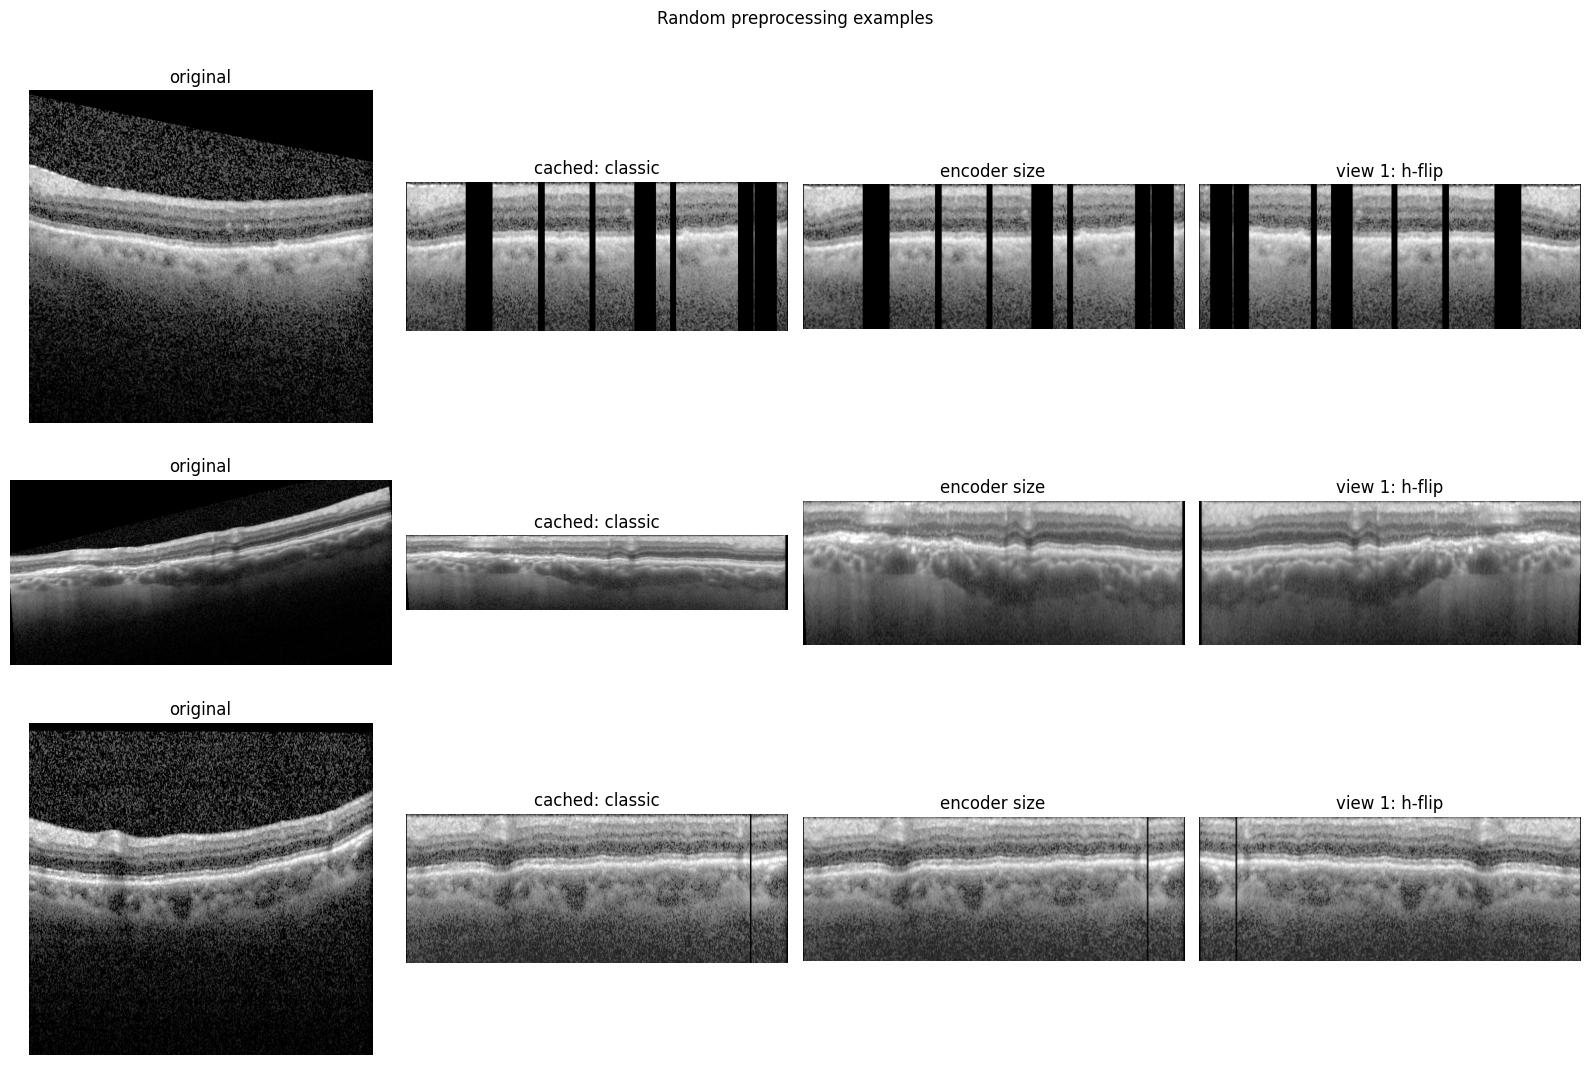

In [ ]:
import random

def show_processed_samples(names, n=3):
    candidates = list(names)
    random.shuffle(candidates)
    picked = []

    for name in candidates:
        cached = cv2.imread(
            cache_path(cfg.preprocess.cache_dir, cfg.preprocess.mode, name),
            cv2.IMREAD_GRAYSCALE,
        )
        if cached is not None:
            picked.append((name, cached))
            if len(picked) == n:
                break

    if not picked:
        raise ValueError("No readable cached images were found.")

    fig, axes = plt.subplots(len(picked), 4, figsize=(16, 3.5 * len(picked)))
    axes = np.atleast_2d(axes)

    for row, (name, cached) in enumerate(picked):
        raw = cv2.imread(str(source_path(name)), cv2.IMREAD_GRAYSCALE)
        resized = cv2.resize(cached, (cfg.encoder.img_size[1], cfg.encoder.img_size[0]))
        panels = [raw, cached, resized, np.fliplr(resized)]
        titles = ["original", f"cached: {cfg.preprocess.mode}", "encoder size", "view 1: h-flip"]

        for ax, panel, title in zip(axes[row], panels, titles):
            ax.imshow(panel, cmap="gray")
            ax.set_title(title)
            ax.axis("off")

        axes[row, 0].set_ylabel(str(name), fontsize=8)
        encoded = preprocess(cached, cfg.encoder.img_size)
        assert encoded.shape == (3, cfg.encoder.img_size[0], cfg.encoder.img_size[1])

    fig.suptitle("Random preprocessing examples", y=1.01)
    fig.tight_layout()

show_processed_samples(images, n=3)

## 4. Extract the resumable DINO feature cache

For this frozen DINO workflow, this prepares reusable features; GPU is recommended and CPU is supported. Each image is encoded once for the identity and horizontal-flip views; training below then runs from cached vectors. Use `--device cuda` on a GPU machine, or `cpu` for a slower check.

In [6]:
FEATURE_DEVICE = 'cuda'  # change to 'cuda' for the required production extraction
run_command('-m', 'mario_dino.features', '--config', CONFIG_PATH, '--device', FEATURE_DEVICE)

$ d:\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.features --config D:\yug_mario\mario\configs\base.yaml --device cuda
libpng error: Read Error
libpng error: Read Error
00:52:10 WARNING mario_dino.octip_cache: Task_1/df_task1_train.csv: excluding 5 row(s) referencing 3 unreadable image(s): ['1BD348C0.png', '3D28DE10.png', 'C250C570.png']
00:53:00 INFO __main__: 17430 unique images, store features/store holds 17434 rows (17429 done)
00:53:07 INFO __main__: chunk 1/1 done (1 images, 7.1s elapsed)
00:53:08 INFO __main__: done: {'images': 17430, 'already_done': 17429, 'encoded': 1}


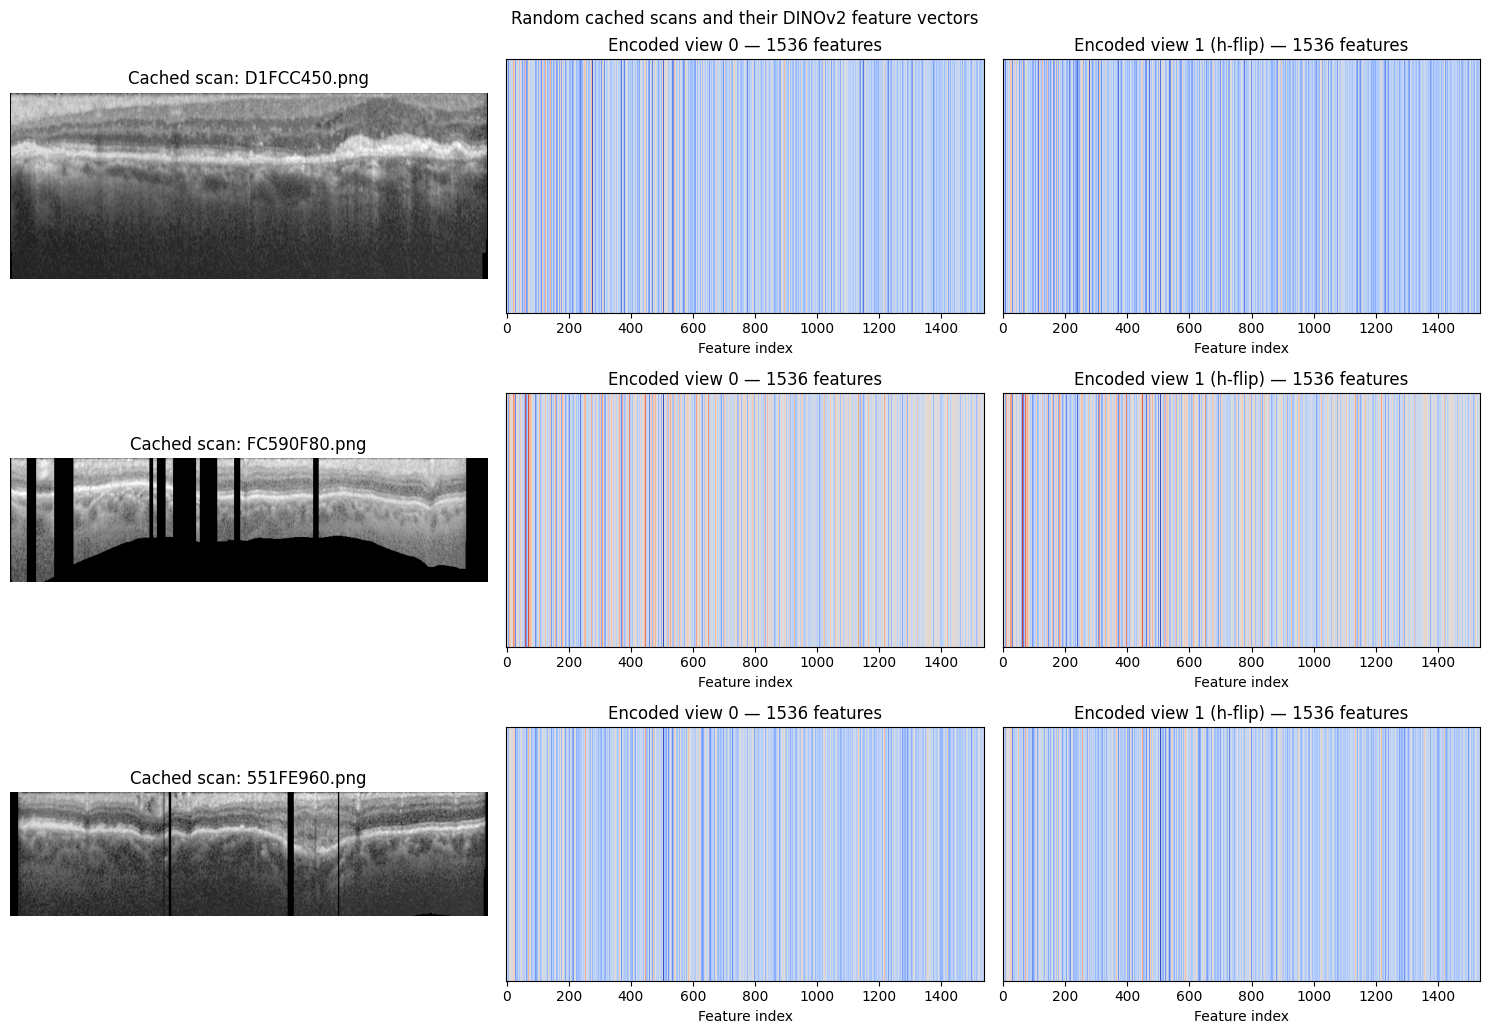

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

from mario_dino.octip_cache import cache_path
from mario_dino.store import FeatureStore

n = 3
store = FeatureStore.open_existing(cfg.features.store_dir)

done_rows = np.flatnonzero(store.done)
if len(done_rows) == 0:
    store.close()
    raise RuntimeError("The feature store has no completed rows yet. Run part 4 first.")

picked_rows = np.random.choice(done_rows, size=min(n, len(done_rows)), replace=False)
names = [store.images[i] for i in picked_rows]
features = store.get(names).astype(np.float32)  # [examples, 2 views, 1536 features]
store.close()

fig, axes = plt.subplots(len(names), 3, figsize=(15, 3.5 * len(names)))
axes = np.atleast_2d(axes)

for row, (name, encoded) in enumerate(zip(names, features)):
    image_path = cache_path(cfg.preprocess.cache_dir, cfg.preprocess.mode, name)
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Could not read cached image: {image_path}")

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"Cached scan: {name}")
    axes[row, 0].axis("off")

    for view, title in enumerate(("Encoded view 0", "Encoded view 1 (h-flip)")):
        axes[row, view + 1].imshow(
            encoded[view][None, :],
            aspect="auto",
            cmap="coolwarm",
            interpolation="nearest",
        )
        axes[row, view + 1].set_title(f"{title} — 1536 features")
        axes[row, view + 1].set_xlabel("Feature index")
        axes[row, view + 1].set_yticks([])

fig.suptitle("Random cached scans and their DINOv2 feature vectors")
fig.tight_layout()
plt.show()

## 5. Train with live training and validation tracking

This calls `train_all` directly so the chart refreshes after every epoch's validation pass. The same events are also flushed to `training_progress.jsonl` in `train.out_dir`, making a run auditable even if the notebook disconnects. Stage A trains Task 1 pairs; Stage B starts from that checkpoint and trains Task 2 rows.

fold 3 | stage_b | epoch 12


,fold,stage,epoch,train_total,train_ce,train_mse,val_F1_score,val_Rk-correlation,val_Specificity,val_loss,val_Quadratic-weighted_Kappa
118,3,stage_b,1,2.136237,2.136237,NaN,0.119483,0.009904,0.666973,1.576468,0.012190
119,3,stage_b,2,1.198389,1.198389,NaN,0.670085,0.050088,0.688202,1.369864,0.024586
120,3,stage_b,3,1.036575,1.036575,NaN,0.569327,0.032018,0.685932,1.365594,-0.012233
121,3,stage_b,4,0.920119,0.920119,NaN,0.575123,0.056336,0.691962,1.490603,0.043687
122,3,stage_b,5,0.846104,0.846104,NaN,0.571110,0.032628,0.682177,1.525998,0.018781
123,3,stage_b,6,0.788032,0.788032,NaN,0.451627,0.046742,0.696171,1.526779,-0.004527
124,3,stage_b,7,0.704560,0.704560,NaN,0.569327,0.035614,0.686144,1.599378,0.003808
125,3,stage_b,8,0.696191,0.696191,NaN,0.634864,0.042943,0.688030,1.704813,0.003789
126,3,stage_b,9,0.577241,0.577241,NaN,0.686580,0.045445,0.683878,2.053359,0.039147
127,3,stage_b,10,0.676626,0.676626,NaN,0.493535,0.005633,0.669357,1.754787,0.004282


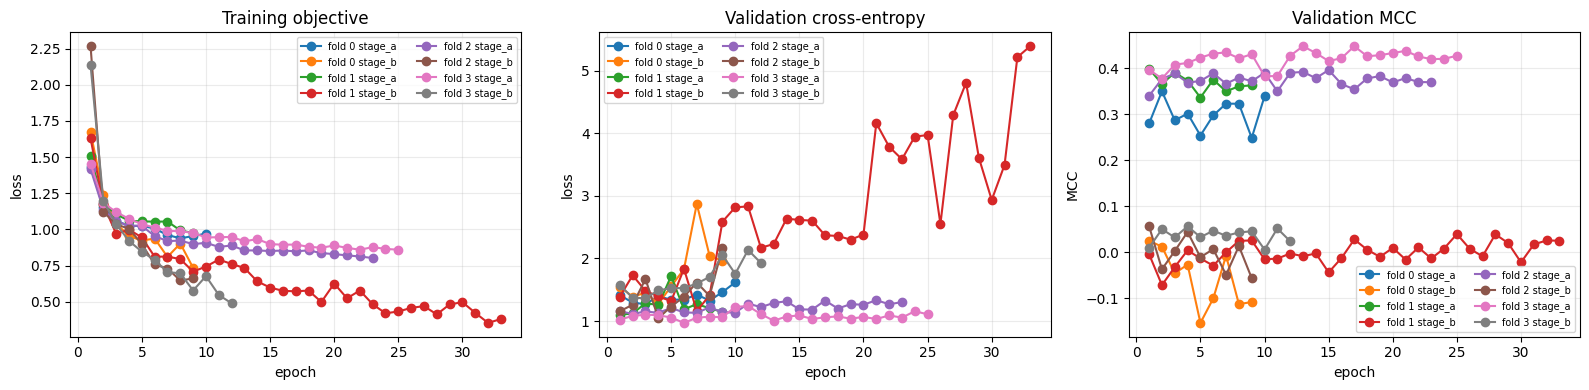

14:24:52 INFO mario_dino.train_heads: fold3 B epoch 12: train_total=0.4888, train_ce=0.4888, val_F1_score=0.5720, val_Rk-correlation=0.0238, val_Specificity=0.6788, val_Quadratic-weighted_Kappa=0.0091, val_loss=1.9277
14:24:53 INFO mario_dino.train_heads: task1 OOF {'F1_score': 0.6181931120160121, 'Rk-correlation': 0.39756614676523133, 'Specificity': 0.8653033905577722}
14:24:53 INFO mario_dino.train_heads: task2 OOF {'F1_score': 0.4010642247246628, 'Rk-correlation': 0.021138310660914157, 'Specificity': 0.6723086541862573, 'Quadratic-weighted_Kappa': 0.037255525321710614}


Training finished. Overall out-of-fold metrics:
{
  "task1": {
    "F1_score": 0.6181931120160121,
    "Rk-correlation": 0.39756614676523133,
    "Specificity": 0.8653033905577722
  },
  "task2": {
    "F1_score": 0.4010642247246628,
    "Rk-correlation": 0.021138310660914157,
    "Specificity": 0.6723086541862573,
    "Quadratic-weighted_Kappa": 0.037255525321710614
  }
}


In [ ]:
from mario_dino.train_heads import train_all

progress_rows = []

def render_progress(event):
    progress_rows.append(event)
    table = pd.DataFrame(progress_rows)
    clear_output(wait=True)
    latest = table.iloc[-1]
    print(f"fold {int(latest.fold)} | {latest.stage} | epoch {int(latest.epoch)}")
    display(table.tail(12).drop(columns=['time'], errors='ignore'))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for (fold, stage), frame in table.groupby(['fold', 'stage']):
        label = f'fold {fold} {stage}'
        axes[0].plot(frame['epoch'], frame.get('train_total'), marker='o', label=label)
        axes[1].plot(frame['epoch'], frame.get('val_loss'), marker='o', label=label)
        if 'val_Rk-correlation' in frame:
            axes[2].plot(frame['epoch'], frame['val_Rk-correlation'], marker='o', label=label)
    axes[0].set(title='Training objective', xlabel='epoch', ylabel='loss')
    axes[1].set(title='Validation cross-entropy', xlabel='epoch', ylabel='loss')
    axes[2].set(title='Validation MCC', xlabel='epoch', ylabel='MCC')
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend(fontsize=7, ncol=2)
    fig.tight_layout()
    plt.show()

# The heads/forecaster are CPU-friendly. Keep this on CPU unless you deliberately change cfg.device.
metrics = train_all(cfg, progress_callback=render_progress)
print('Training finished. Overall out-of-fold metrics:')
print(json.dumps({'task1': metrics['task1'].get('oof'), 'task2': metrics['task2'].get('oof')}, indent=2))

## 6. Review final validation predictions

These are out-of-fold predictions: every row was predicted by a checkpoint that did not train on that patient's fold.

,task,F1_score,Rk-correlation,Specificity,Quadratic-weighted_Kappa
0,Task 1,0.618193,0.397566,0.865303,NaN
1,Task 2,0.401064,0.021138,0.672309,0.037256


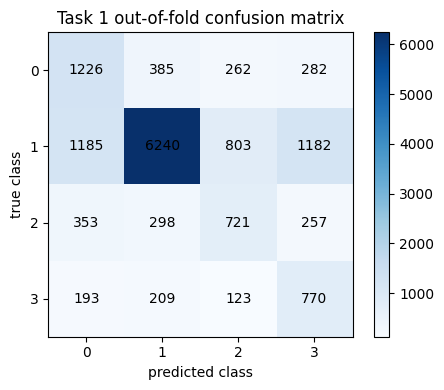

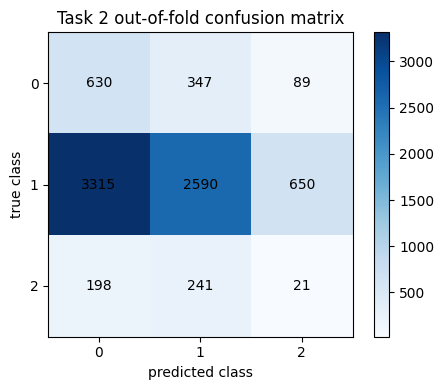

In [ ]:
heads_dir = Path(cfg.train.out_dir)
all_metrics = json.loads((heads_dir / 'metrics.json').read_text(encoding='utf-8'))
display(pd.DataFrame([
    {'task': 'Task 1', **all_metrics['task1'].get('oof', {})},
    {'task': 'Task 2', **all_metrics['task2'].get('oof', {})},
]))

for task, classes in [(1, 4), (2, 3)]:
    path = heads_dir / f'oof_task{task}.csv'
    if not path.exists():
        continue
    oof = pd.read_csv(path)
    cm = confusion_matrix(oof.y_true, oof.y_pred, labels=np.arange(classes))
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(cm, cmap='Blues')
    for (r, c), value in np.ndenumerate(cm):
        ax.text(c, r, str(value), ha='center', va='center')
    ax.set(title=f'Task {task} out-of-fold confusion matrix', xlabel='predicted class', ylabel='true class',
           xticks=np.arange(classes), yticks=np.arange(classes))
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    plt.show()

## Optional: challenge inference

After reviewing the out-of-fold results, run inference with the configured challenge CSVs. It reuses feature-cache entries when they overlap with Task 1.

## Alternative encoder training on the cloud instance

The executable cells above retain the DINO frozen-feature workflow. Their previews use the legacy
DINO transform, weight preparation assumes timm DINO weights, and training reads the feature store.
Changing only the config path does not turn this dashboard into full encoder fine-tuning or provide
live tracking for `train_finetune`. Use these separate CLI commands from the repository root instead:

```bash
python scripts/fetch_weights.py --config configs/task1_convnext.yaml
python -m mario_dino.data.splits --config configs/task1_convnext.yaml
python -m mario_dino.train_finetune --config configs/task1_convnext.yaml --device cuda
python -m mario_dino.infer --config configs/task1_convnext.yaml --task 1 --csv /path/to/task1.csv --device cuda
```

For VisionFM OCT, manually prepare `weights/VFM_OCT_weights.pth`, then use
`configs/task1_visionfm.yaml`. That preset assumes raw backbone weights; select
`--set encoder.checkpoint_key=teacher` (or `student` / `visionfm_state_dict`) only for a file
with that wrapper. The released OCT layout remains unverified. Wrapped Namespace metadata needs
PyTorch >=2.4. The new presets use their own input transforms and `[192, 512]` inputs.

`train_finetune` reads cached image pairs, trains Task 1 encoder/heads together and writes history,
OOF predictions and self-contained `fold{k}/task1.pt` files to `outputs/convnext_finetune` or
`outputs/visionfm_finetune`. It does not use pooled features or prefix tokens. Inference loads
one fold encoder at a time using its saved transform and needs no original source weight file.
`train_partial` remains DINO-only. DINO-trained heads are not interchangeable with these encoders.
For a frozen alternative baseline, follow the runbook and override inference `--run-dir` to its
`outputs/convnext_heads` or `outputs/visionfm_heads` directory.

See [the encoder reference](../docs/encoders.md) and
[cloud instructions](../RUNBOOK.md#alternative-task-1-encoders-convnext-and-visionfm-oct).
These are commands for later execution. No notebook cells, CPU/GPU models, training, inference,
pretrained binaries or new runtime tests were run to document this extension. Saved outputs
in this notebook predate it and do not validate the alternative encoders.


In [ ]:
run_command('-m', 'mario_dino.infer', '--config', CONFIG_PATH, '--task', '1', '--device', 'auto')
run_command('-m', 'mario_dino.infer', '--config', CONFIG_PATH, '--task', '2', '--device', 'auto')
print('Uncomment the two commands above only when the configured inference CSV paths are ready.')

Uncomment the two commands above only when the configured inference CSV paths are ready.


## 7. Alternative encoders: ConvNeXt-Tiny and VisionFM

The cells below add the two implemented alternatives alongside the DINOv2 results. Full Task 1 fine-tuning uses `mario_dino.train_finetune` on cached image pairs and writes checkpoints, per-fold histories, out-of-fold predictions, and metrics to each encoder's configured `finetune.out_dir`. It does **not** train from or require the feature cache. Separate opt-in cells can extract frozen features into each encoder's own labeled `features.store_dir`.

ConvNeXt pretrained weights can be prepared with `scripts/fetch_weights.py --config configs/task1_convnext.yaml`. VisionFM OCT weights must be obtained and placed manually as described in `docs/encoders.md`. The status cell reports missing prerequisites before either operation.

In [5]:
from mario_dino.config import load_config

ALT_ENCODER_CONFIGS = {
    "convnext": REPO / "configs" / "task1_convnext.yaml",
    "visionfm": REPO / "configs" / "task1_visionfm.yaml",
}
alt_cfgs = {name: load_config(str(path)) for name, path in ALT_ENCODER_CONFIGS.items()}

# Verify cache identity and actual files, not just the configured directory names.
cache_configs = [("dinov2", cfg), *[(name, alt_cfgs[name]) for name in ALT_ENCODER_CONFIGS]]
cache_rows = []
cache_roots = []
for name, encoder_cfg in cache_configs:
    root = (REPO / encoder_cfg.features.store_dir).resolve()
    cache_roots.append(root)
    meta_path = root / "meta.json"
    identity = {}
    row_shape = None
    n_rows = n_done = 0
    if meta_path.is_file():
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
        identity = meta.get("identity", {})
        row_shape = meta.get("row_shape")
        index_path, done_path = root / "index.csv", root / "done.npy"
        n_rows = len(pd.read_csv(index_path)) if index_path.is_file() else 0
        n_done = int(np.load(done_path).sum()) if done_path.is_file() else 0
    expected_kind = "dinov2" if name == "dinov2" else name
    cache_rows.append({
        "encoder": name,
        "configured_cache": str(root.relative_to(REPO)),
        "cache_present": meta_path.is_file(),
        "rows": n_rows,
        "completed": n_done,
        "row_shape": row_shape,
        "metadata_encoder": identity.get("encoder"),
        "metadata_kind": identity.get("encoder_kind", "dinov2" if name == "dinov2" else None),
        "identity_matches_config": (
            identity.get("encoder") == encoder_cfg.encoder.name
            and identity.get("encoder_kind", expected_kind) == expected_kind
        ) if meta_path.is_file() else None,
        "weights_present": bool(encoder_cfg.encoder.weights and (REPO / encoder_cfg.encoder.weights).is_file()),
    })
assert len(set(cache_roots)) == len(cache_roots), "Encoder feature caches must use distinct directories."
display(pd.DataFrame(cache_rows))
print("The alternative feature stores are separately configured as features/convnext and features/visionfm.")
print("Full fine-tuning below consumes cached images, not these frozen-feature stores.")

,encoder,configured_cache,cache_present,rows,completed,row_shape,metadata_encoder,metadata_kind,identity_matches_config,weights_present
0,dinov2,features\store,True,17434,17430,"[2, 1536]",vit_base_patch14_reg4_dinov2.lvd142m,dinov2,True,True
1,convnext,features\convnext,False,0,0,None,None,None,None,True
2,visionfm,features\visionfm,False,0,0,None,None,None,None,True


The alternative feature stores are separately configured as features/convnext and features/visionfm.
Full fine-tuning below consumes cached images, not these frozen-feature stores.


### 7a. Optional: extract frozen features into encoder-specific stores

Set `ENCODERS_TO_CACHE` to one or both names to run the existing feature extractor. Each config supplies a distinct store path and the store metadata fingerprints encoder kind/name, weights, preprocessing, pooling, and views. This is a separate frozen-feature baseline; it is not a prerequisite for full fine-tuning.

In [7]:
# Leave empty to inspect only. Choose from ["convnext", "visionfm"] to start feature extraction.
ENCODERS_TO_CACHE = []
_unknown = set(ENCODERS_TO_CACHE) - set(ALT_ENCODER_CONFIGS)
if _unknown:
    raise ValueError(f"Unknown encoder selection: {sorted(_unknown)}")
if not ENCODERS_TO_CACHE:
    print("No feature extraction requested. The cache-status table above shows current stores and labels.")
else:
    _missing_weights = []
    for _name in ENCODERS_TO_CACHE:
        _encoder_cfg = alt_cfgs[_name].encoder
        _weight_path = REPO / _encoder_cfg.weights if _encoder_cfg.weights else None
        if _weight_path is None or not _weight_path.is_file():
            _missing_weights.append((_name, str(_weight_path or "no weights configured")))
    if _missing_weights:
        raise FileNotFoundError("Prepare encoder weights before extraction: " + "; ".join(
            f"{name}: {weight}" for name, weight in _missing_weights
        ))
    for _name in ENCODERS_TO_CACHE:
        print(f"Extracting {_name} into {alt_cfgs[_name].features.store_dir}", flush=True)
        run_command("-m", "mario_dino.features", "--config", ALT_ENCODER_CONFIGS[_name], "--device", "auto")

No feature extraction requested. The cache-status table above shows current stores and labels.


### 7b. Full Task 1 fine-tuning

Enable one or both encoders in `ENCODERS_TO_FINETUNE` after their pretrained weights are available. Each run performs the configured patient-held-out folds, streams epoch/validation logs, and saves a self-contained best checkpoint per fold. Defaults stay empty to avoid accidentally launching lengthy GPU training when running the notebook top-to-bottom.

In [7]:
# Set to ["convnext", "visionfm"] (or just one) when ready to launch full fine-tuning.
ENCODERS_TO_FINETUNE = ["visionfm"]
_unknown = set(ENCODERS_TO_FINETUNE) - set(ALT_ENCODER_CONFIGS)
if _unknown:
    raise ValueError(f"Unknown encoder selection: {sorted(_unknown)}")
if not ENCODERS_TO_FINETUNE:
    print("No fine-tuning requested. Set ENCODERS_TO_FINETUNE after preparing the selected pretrained weights.")
else:
    _missing_weights = []
    for _name in ENCODERS_TO_FINETUNE:
        _encoder_cfg = alt_cfgs[_name].encoder
        _weight_path = REPO / _encoder_cfg.weights if _encoder_cfg.weights else None
        if _weight_path is None or not _weight_path.is_file():
            _missing_weights.append((_name, str(_weight_path or "no weights configured")))
    if _missing_weights:
        raise FileNotFoundError("Prepare encoder weights before training: " + "; ".join(
            f"{name}: {weight}" for name, weight in _missing_weights
        ))
    for _name in ENCODERS_TO_FINETUNE:
        print(f"Fine-tuning {_name}; results will be saved to {alt_cfgs[_name].finetune.out_dir}", flush=True)
        run_command("-m", "mario_dino.train_finetune", "--config", ALT_ENCODER_CONFIGS[_name], "--device", "auto")

Fine-tuning visionfm; results will be saved to outputs/visionfm_finetune
$ d:\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.train_finetune --config D:\yug_mario\mario\configs\task1_visionfm.yaml --device auto
libpng error: Read Error
libpng error: Read Error
00:26:30 WARNING __main__: excluded pairs referencing unreadable images: ['1BD348C0.png', '3D28DE10.png', 'C250C570.png']
00:26:31 INFO mario_dino.octip_cache: classic cache: 17430 images, 17430 already cached, 0 to process
[W1106 00:26:39.000000000 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 58720256 bytes (free: 0, total: 4294443008).
[W1106 00:26:39.000000000 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 58720256 bytes (free: 0, total: 4294443008).
[W1106 00:26:39.000000000 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 58720256 bytes (free: 0, total: 42

RuntimeError: Command failed with exit code 1: d:\yug_mario\mario\.venv\Scripts\python.exe -m mario_dino.train_finetune --config D:\yug_mario\mario\configs\task1_visionfm.yaml --device auto

### 7c. Compare validation results and inspect training curves

Run this after any selected fine-tuning jobs finish. It reads the saved out-of-fold metrics/predictions and per-fold histories, plots training loss, validation loss, and validation MCC, and compares each available Task 1 result with the frozen DINOv2 run. Missing result files are reported as not yet available; no alternative-encoder results are inferred from the DINO run.

visionfm: no metrics yet (outputs\visionfm_finetune\metrics.json)


,n,F1_score,Rk-correlation,Specificity
run,,,,
DINOv2 frozen-feature,14489,0.618193,0.397566,0.865303
convnext,14491,0.773998,0.586007,0.902522


,Rk-correlation,delta_vs_DINOv2
run,,
DINOv2 frozen-feature,0.397566,0.000000
convnext,0.586007,0.188441


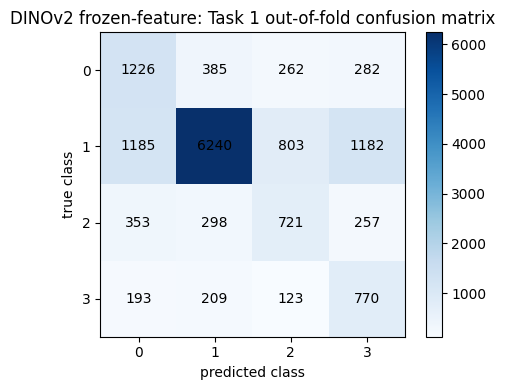

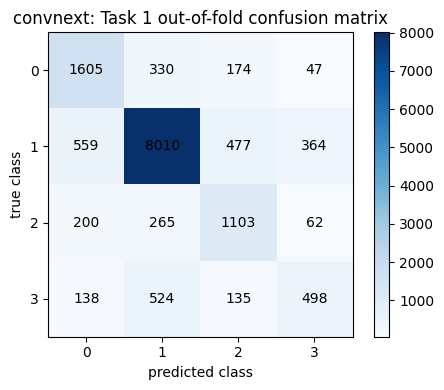

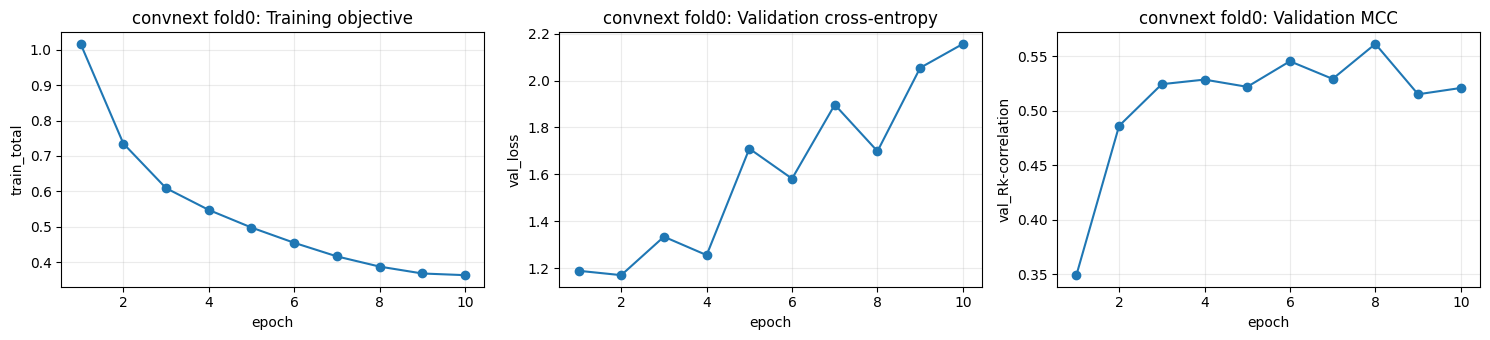

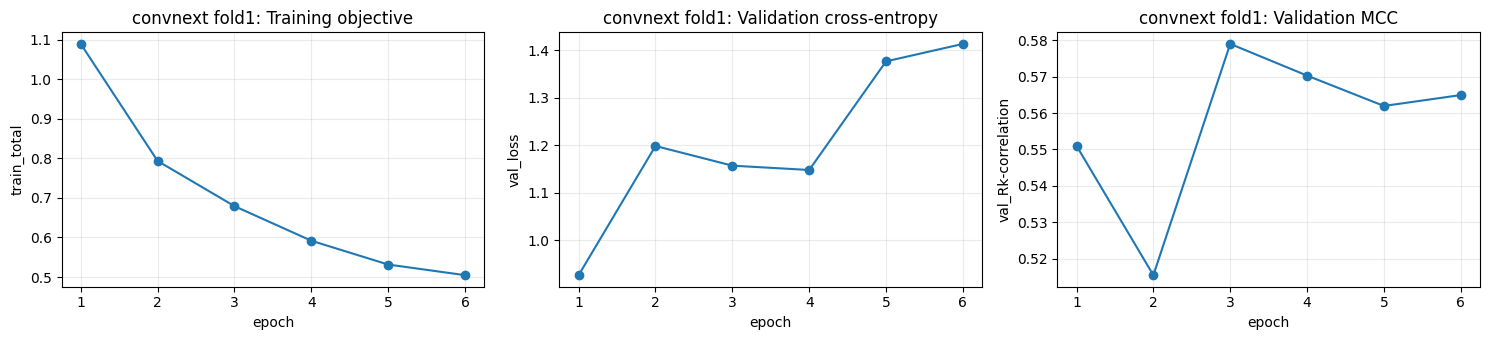

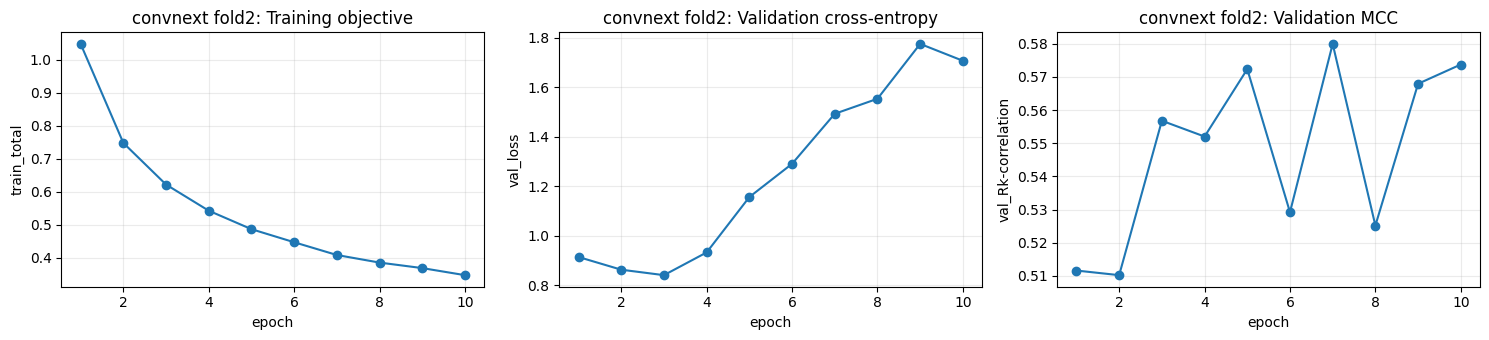

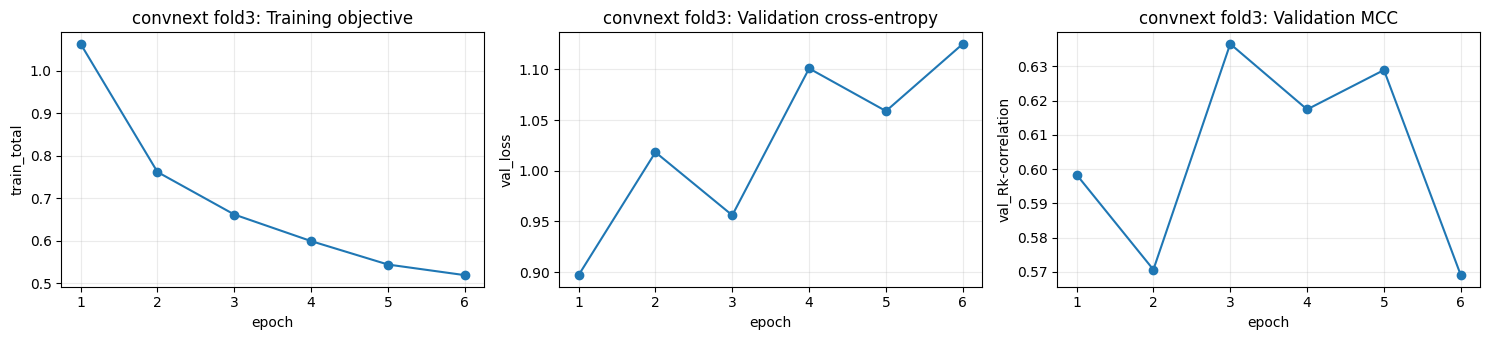

In [5]:
from pathlib import Path

result_dirs = {"DINOv2 frozen-feature": Path(cfg.train.out_dir)}
result_dirs.update({name: Path(alt_cfgs[name].finetune.out_dir) for name in ALT_ENCODER_CONFIGS})
result_dirs["ConvNeXt fine-tuned embeddings + heads"] = Path("outputs/convnext_finetuned_heads")
metric_rows = []
result_frames = {}

for name, result_dir in result_dirs.items():
    metrics_path = result_dir / "metrics.json"
    if not metrics_path.is_file():
        print(f"{name}: no metrics yet ({metrics_path})")
        continue
    metrics_doc = json.loads(metrics_path.read_text(encoding="utf-8"))
    task1 = metrics_doc.get("task1", {})
    oof_metrics = task1.get("oof", {})
    metric_rows.append({"run": name, "n": task1.get("n"), **oof_metrics})
    predictions_path = result_dir / "oof_task1.csv"
    if predictions_path.is_file():
        result_frames[name] = pd.read_csv(predictions_path)

if metric_rows:
    metrics_table = pd.DataFrame(metric_rows).set_index("run")
    display(metrics_table)
    if "DINOv2 frozen-feature" in metrics_table.index and "Rk-correlation" in metrics_table:
        dino_mcc = metrics_table.loc["DINOv2 frozen-feature", "Rk-correlation"]
        display(pd.DataFrame({
            "Rk-correlation": metrics_table["Rk-correlation"],
            "delta_vs_DINOv2": metrics_table["Rk-correlation"] - dino_mcc,
        }))
else:
    print("No Task 1 metrics files are available yet.")

for name, frame in result_frames.items():
    cm = confusion_matrix(frame.y_true, frame.y_pred, labels=np.arange(4))
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(cm, cmap="Blues")
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, str(value), ha="center", va="center")
    ax.set(title=f"{name}: Task 1 out-of-fold confusion matrix", xlabel="predicted class",
           ylabel="true class", xticks=np.arange(4), yticks=np.arange(4))
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    plt.show()

history_rows = []
for name in ALT_ENCODER_CONFIGS:
    run_dir = Path(alt_cfgs[name].finetune.out_dir)
    for history_path in sorted(run_dir.glob("fold*/history.json")):
        fold_name = history_path.parent.name
        history = pd.DataFrame(json.loads(history_path.read_text(encoding="utf-8")))
        if history.empty:
            continue
        history["fold"] = fold_name
        history["encoder"] = name
        history_rows.append(history)
        fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
        for ax, metric, title in zip(
            axes,
            ("train_total", "val_loss", "val_Rk-correlation"),
            ("Training objective", "Validation cross-entropy", "Validation MCC"),
        ):
            if metric in history:
                ax.plot(history["epoch"], history[metric], marker="o")
            ax.set(title=f"{name} {fold_name}: {title}", xlabel="epoch", ylabel=metric)
            ax.grid(alpha=.25)
        fig.tight_layout()
        plt.show()

if not history_rows:
    print("No alternative-encoder training histories are available yet.")

## 8. Train heads from fold-specific fine-tuned ConvNeXt embeddings

This uses the encoder weights from `outputs/convnext_finetune/fold{k}/task1.pt`?not the original-pretrained `features/convnext` cache. For each cross-validation fold, the matching fine-tuned encoder extracts train and held-out embeddings; the new MARIO heads then train on that fold's embeddings using the GPU. Fold-specific caches are stored separately under `features/convnext_finetuned_heads/`, and head checkpoints, histories, OOF predictions, and combined metrics go to `outputs/convnext_finetuned_heads/`. Run after all ConvNeXt fine-tuning folds are complete and the processed image cache is available.

Fine-tuned ConvNeXt embeddings | GPU | fold 3 | stage_b | epoch 16


,fold,stage,epoch,train_total,train_ce,train_mse,val_F1_score,val_Rk-correlation,val_Specificity,val_loss,val_Quadratic-weighted_Kappa
98,3,stage_b,5,0.802072,0.802072,NaN,0.635027,0.090065,0.703523,1.299993,0.088645
99,3,stage_b,6,0.734870,0.734870,NaN,0.478164,0.123236,0.728019,1.198768,0.079337
100,3,stage_b,7,0.731497,0.731497,NaN,0.694742,0.088322,0.701569,1.407190,0.063886
101,3,stage_b,8,0.644039,0.644039,NaN,0.696524,0.159647,0.729784,1.540214,0.144612
102,3,stage_b,9,0.594349,0.594349,NaN,0.684938,0.115534,0.716769,1.547867,0.048297
103,3,stage_b,10,0.589534,0.589534,NaN,0.522282,0.124716,0.724513,1.578883,0.100704
104,3,stage_b,11,0.570573,0.570573,NaN,0.727273,0.095254,0.695844,1.917250,0.130479
105,3,stage_b,12,0.531581,0.531581,NaN,0.626560,0.116749,0.719191,1.889053,0.086031
106,3,stage_b,13,0.474502,0.474502,NaN,0.652406,0.135388,0.726997,2.133713,0.093066
107,3,stage_b,14,0.514162,0.514162,NaN,0.630125,0.124519,0.713816,2.013536,0.156129


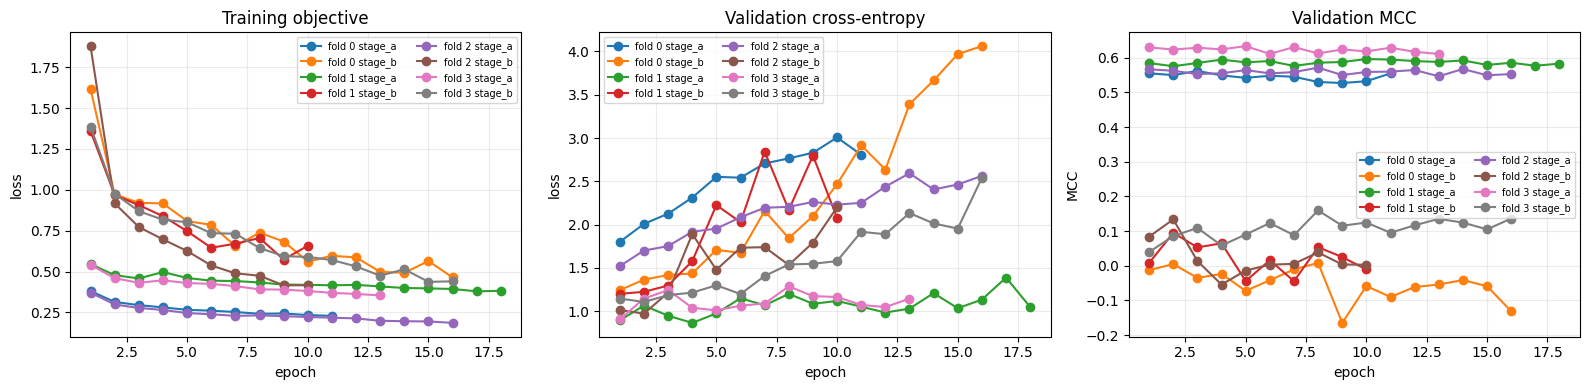

11:57:28 INFO mario_dino.train_heads: fold3 B epoch 16: train_total=0.4404, train_ce=0.4404, val_F1_score=0.6903, val_Rk-correlation=0.1363, val_Specificity=0.7204, val_Quadratic-weighted_Kappa=0.1247, val_loss=2.5414
11:57:28 INFO mario_dino.train_heads: task1 OOF {'F1_score': 0.8091176470588235, 'Rk-correlation': 0.6336111390655537, 'Specificity': 0.913384437508193}
11:57:28 INFO mario_dino.train_heads: task2 OOF {'F1_score': 0.696524064171123, 'Rk-correlation': 0.15964695656354547, 'Specificity': 0.7297838846144038, 'Quadratic-weighted_Kappa': 0.1446118674010185}


Fine-tuned ConvNeXt embedding head training finished. Overall out-of-fold metrics:
{
  "task1": {
    "F1_score": 0.7773790628666069,
    "Rk-correlation": 0.5902901006633257,
    "Specificity": 0.902881838274626
  },
  "task2": {
    "F1_score": 0.5967582281613462,
    "Rk-correlation": 0.114341232208503,
    "Specificity": 0.7148030186741328,
    "Quadratic-weighted_Kappa": 0.09964581758053048
  }
}
Saved fold heads, histories, OOF predictions, and metrics to D:\yug_mario\mario\outputs\convnext_finetuned_heads


In [10]:
import copy
import gc
import hashlib

import torch

from mario_dino.data.images import N_VIEWS, resolve_input_spec
from mario_dino.features import encode_views, extract_features
from mario_dino.models.encoder import sha256_file
from mario_dino.models.finetuned import load_finetuned_checkpoint
from mario_dino.octip_cache import collect_images
from mario_dino.store import FeatureStore
from mario_dino.train_heads import _metrics, train_all
from mario_dino.utils import write_json, write_provenance

convnext_heads_cfg = load_config(str(ALT_ENCODER_CONFIGS["convnext"]))
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required by this cell to train the heads on the GPU.")
convnext_device = torch.device("cuda")

convnext_finetune_dir = REPO / convnext_heads_cfg.finetune.out_dir
convnext_finetune_metrics_path = convnext_finetune_dir / "metrics.json"
if not convnext_finetune_metrics_path.is_file():
    raise FileNotFoundError(f"ConvNeXt fine-tuning results not found: {convnext_finetune_metrics_path}")
convnext_finetune_metrics = json.loads(convnext_finetune_metrics_path.read_text(encoding="utf-8"))
convnext_folds = [int(fold) for fold in convnext_finetune_metrics.get("folds", [])]
if not convnext_folds:
    raise ValueError("The ConvNeXt fine-tuning metrics contain no completed folds.")
convnext_checkpoints = {
    fold: convnext_finetune_dir / f"fold{fold}" / "task1.pt" for fold in convnext_folds
}
missing_checkpoints = [str(path) for path in convnext_checkpoints.values() if not path.is_file()]
if missing_checkpoints:
    raise FileNotFoundError("Fine-tuned ConvNeXt checkpoints are missing:\n" + "\n".join(missing_checkpoints))

convnext_checkpoint_hashes = {
    fold: sha256_file(str(checkpoint)) for fold, checkpoint in convnext_checkpoints.items()
}
convnext_run_tag = hashlib.sha256(
    "".join(f"{fold}:{convnext_checkpoint_hashes[fold]}" for fold in convnext_folds).encode("ascii")
).hexdigest()[:12]
convnext_feature_root = REPO / "features" / "convnext" / "finetuned_heads" / convnext_run_tag
convnext_heads_out = REPO / "outputs" / "convnext_finetuned_heads"
convnext_heads_cfg.device = "cuda"
convnext_heads_cfg.train.folds = convnext_folds
convnext_heads_cfg.train.out_dir = str(convnext_heads_out)

convnext_csvs = convnext_heads_cfg.data.task1_train_csvs + convnext_heads_cfg.data.task2_train_csvs
convnext_images = collect_images(
    convnext_csvs,
    convnext_heads_cfg.data.image_roots,
    convnext_heads_cfg.data.include_image_dirs,
)
if not convnext_images:
    raise ValueError("No readable images were found in the configured Task 1/Task 2 training CSVs.")

convnext_head_progress = []
convnext_fold_oof_task1 = []
convnext_fold_oof_task2 = []
convnext_best_epochs = {}


def render_convnext_head_progress(event):
    convnext_head_progress.append(event)
    table = pd.DataFrame(convnext_head_progress)
    latest = table.iloc[-1]
    clear_output(wait=True)
    print(
        f"Fine-tuned ConvNeXt embeddings | GPU | fold {int(latest.fold)} "
        f"| {latest.stage} | epoch {int(latest.epoch)}"
    )
    display(table.tail(12).drop(columns=["time"], errors="ignore"))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for (fold, stage), frame in table.groupby(["fold", "stage"]):
        label = f"fold {fold} {stage}"
        axes[0].plot(frame["epoch"], frame["train_total"], marker="o", label=label)
        axes[1].plot(frame["epoch"], frame["val_loss"], marker="o", label=label)
        if "val_Rk-correlation" in frame:
            axes[2].plot(frame["epoch"], frame["val_Rk-correlation"], marker="o", label=label)
    axes[0].set(title="Training objective", xlabel="epoch", ylabel="loss")
    axes[1].set(title="Validation cross-entropy", xlabel="epoch", ylabel="loss")
    axes[2].set(title="Validation MCC", xlabel="epoch", ylabel="MCC")
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend(fontsize=7, ncol=2)
    fig.tight_layout()
    plt.show()


for fold in convnext_folds:
    checkpoint_path = convnext_checkpoints[fold]
    print(f"\nFold {fold}: extracting embeddings from {checkpoint_path}", flush=True)
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    finetuned_net = load_finetuned_checkpoint(checkpoint, device="cpu")
    encoder = finetuned_net.encoder.to(convnext_device).eval()
    del finetuned_net, checkpoint
    gc.collect()

    fold_feature_store_path = convnext_feature_root / f"fold{fold}"
    fold_identity = {
        "encoder": convnext_heads_cfg.encoder.name,
        "encoder_kind": "convnext",
        "representation_source": "fold-specific fine-tuned encoder checkpoint",
        "fine_tuned_fold": fold,
        "fine_tuned_checkpoint_sha256": convnext_checkpoint_hashes[fold],
        "img_size_hw": list(convnext_heads_cfg.encoder.img_size),
        "input_spec": resolve_input_spec(convnext_heads_cfg.encoder),
        "preprocess_mode": convnext_heads_cfg.preprocess.mode,
        "pooling": "native average pool and final normalization",
        "views": ["identity", "hflip"],
    }
    fold_store = FeatureStore(
        str(fold_feature_store_path),
        row_shape=(N_VIEWS, encoder.out_dim),
        dtype=convnext_heads_cfg.features.dtype,
        identity=fold_identity,
    )
    try:
        extraction_stats = extract_features(
            encoder,
            convnext_images,
            fold_store,
            convnext_heads_cfg.preprocess.cache_dir,
            convnext_heads_cfg.preprocess.mode,
            convnext_heads_cfg.encoder.img_size,
            convnext_device,
            batch_size=convnext_heads_cfg.features.batch_size,
            chunk_size=convnext_heads_cfg.features.chunk_size,
            num_workers=0,  # Avoid Windows/Jupyter multiprocessing worker crashes.
            amp=convnext_heads_cfg.features.amp,
            encode_fn=lambda batch, model=encoder: encode_views(
                model, batch, convnext_device, convnext_heads_cfg.features.amp
            ),
            input_spec=resolve_input_spec(convnext_heads_cfg.encoder),
        )
        if not fold_store.done.all():
            raise RuntimeError(
                f"Fold {fold} feature extraction is incomplete: "
                f"{int(fold_store.done.sum())}/{len(fold_store)} images."
            )
    finally:
        fold_store.close()
    print(f"Fold {fold} feature extraction: {extraction_stats}", flush=True)

    encoder.cpu()
    del encoder
    gc.collect()
    torch.cuda.empty_cache()

    fold_cfg = copy.deepcopy(convnext_heads_cfg)
    fold_cfg.train.folds = [fold]
    print(f"Training Task 1/Task 2 heads on CUDA for fold {fold}.", flush=True)
    fold_metrics = train_all(
        fold_cfg,
        store_dir=str(fold_feature_store_path),
        folds=[fold],
        progress_callback=render_convnext_head_progress,
    )
    convnext_fold_oof_task1.append(pd.read_csv(convnext_heads_out / "oof_task1.csv"))
    if fold_metrics.get("task2", {}).get("n", 0):
        convnext_fold_oof_task2.append(pd.read_csv(convnext_heads_out / "oof_task2.csv"))
    convnext_best_epochs.update(fold_metrics.get("best_epochs", {}))

convnext_oof_task1 = pd.concat(convnext_fold_oof_task1, ignore_index=True)
convnext_oof_task1.to_csv(convnext_heads_out / "oof_task1.csv", index=False)
if convnext_fold_oof_task2:
    convnext_oof_task2 = pd.concat(convnext_fold_oof_task2, ignore_index=True)
    convnext_oof_task2.to_csv(convnext_heads_out / "oof_task2.csv", index=False)
else:
    convnext_oof_task2 = pd.DataFrame()

convnext_head_metrics = {
    "folds": convnext_folds,
    "select_metric": convnext_heads_cfg.train.select_metric,
    "ablation": {
        "head_input": convnext_heads_cfg.model.head_input,
        "forecaster": convnext_heads_cfg.model.forecaster,
        "lambda_pred": convnext_heads_cfg.train.lambda_pred,
    },
    "best_epochs": convnext_best_epochs,
    "task1": _metrics([convnext_oof_task1], 1),
    "task2": _metrics([convnext_oof_task2], 2) if not convnext_oof_task2.empty else {},
}
write_json(str(convnext_heads_out / "metrics.json"), convnext_head_metrics)
with (convnext_heads_out / "training_progress.jsonl").open("w", encoding="utf-8") as progress_file:
    for event in convnext_head_progress:
        progress_file.write(json.dumps(event, default=lambda value: value.item() if hasattr(value, "item") else str(value)) + "\n")
write_provenance(
    str(convnext_heads_out),
    convnext_heads_cfg,
    {
        "folds": convnext_folds,
        "device": str(convnext_device),
        "representation_source": "fold-specific fine-tuned ConvNeXt checkpoints",
        "fine_tuned_checkpoint_sha256": convnext_checkpoint_hashes,
        "feature_stores": {fold: str(convnext_feature_root / f"fold{fold}") for fold in convnext_folds},
    },
)
print("Fine-tuned ConvNeXt embedding head training finished. Overall out-of-fold metrics:")
print(json.dumps({
    "task1": convnext_head_metrics["task1"].get("oof"),
    "task2": convnext_head_metrics["task2"].get("oof"),
}, indent=2))
print(f"Saved fold heads, histories, OOF predictions, and metrics to {convnext_heads_out}")